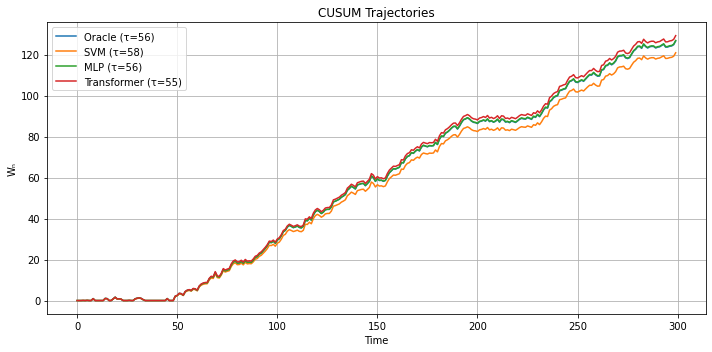

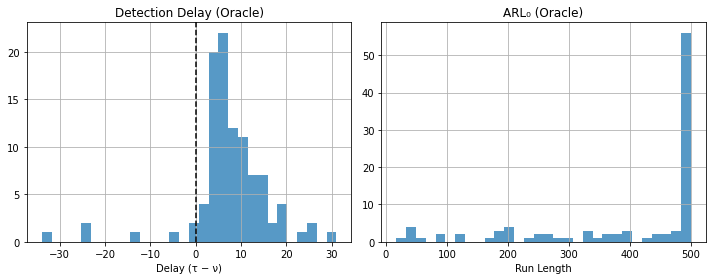

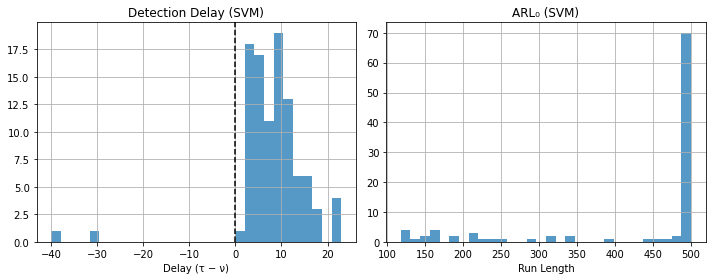

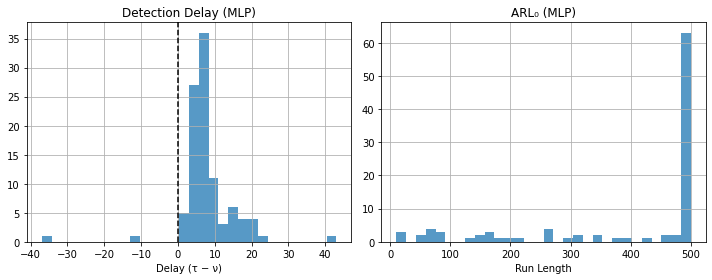

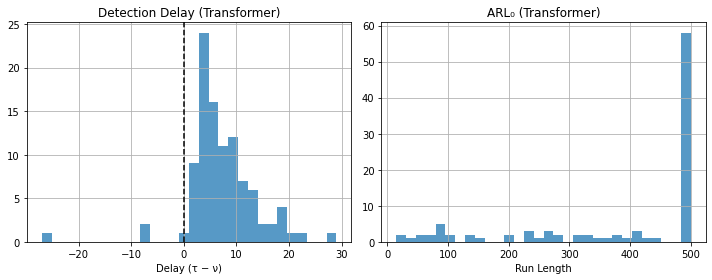

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
import os

# === True Distributions ===
mu0, mu1, sigma = 0.0, 1.0, 1.0
p = lambda x: norm.pdf(x, loc=mu1, scale=sigma)
q = lambda x: norm.pdf(x, loc=mu0, scale=sigma)
true_llr = lambda x: np.log(p(x) / q(x))

# === Generate Data ===
def generate_data(n_p=300, n_q=300):
    X_p = np.random.normal(mu1, sigma, size=(n_p, 1))
    X_q = np.random.normal(mu0, sigma, size=(n_q, 1))
    X = np.vstack([X_p, X_q])
    y = np.hstack([np.ones(n_p), np.zeros(n_q)])
    return X, y

# === MLP (2-layer ReLU NN) ===
class MLPRegressorTorch(nn.Module):
    def __init__(self, d_in=1, d_hidden=32):
        super().__init__()
        self.fc1 = nn.Linear(d_in, d_hidden)
        self.fc2 = nn.Linear(d_hidden, 1)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        return self.fc2(x).squeeze(-1)

# === Transformer Regressor ===
class TransformerRegressor(nn.Module):
    def __init__(self, d_input=1, d_model=16, nhead=2, num_layers=2):
        super().__init__()
        self.embedding = nn.Linear(d_input, d_model)
        encoder_layer = nn.TransformerEncoderLayer(d_model, nhead, batch_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers)
        self.fc_out = nn.Linear(d_model, 1)

    def forward(self, x):
        if len(x.shape) == 2:
            x = x.unsqueeze(1)  # shape [B, 1, d_input]
        x = self.embedding(x)  # [B, 1, d_model]
        x = self.encoder(x)    # [B, 1, d_model]
        return self.fc_out(x[:, 0]).squeeze(-1)  # [B]

# === Training Function ===
def train_model(model, X, y, epochs=100, lr=1e-3):
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    X_torch = torch.tensor(X, dtype=torch.float32)
    y_torch = torch.tensor(y, dtype=torch.float32).view(-1)
    loader = DataLoader(TensorDataset(X_torch, y_torch), batch_size=32, shuffle=True)
    for epoch in range(epochs):
        for xb, yb in loader:
            yb = yb.view(-1)
            pred = model(xb)
            loss = loss_fn(pred, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

# === CuSum ===
def run_cusum(llr_func, stream, threshold):
    W = np.zeros(len(stream))
    tau = None
    for n in range(1, len(stream)):
        llr = llr_func(stream[n:n+1])
        W[n] = max(0, W[n-1] + llr)
        if tau is None and W[n] >= threshold:
            tau = n
    return W, tau

# === Delay & ARL Simulation ===
def simulate_delay(llr_func, threshold=5.0, n_trials=100, change_point=50, total_len=300):
    delays = []
    for _ in range(n_trials):
        stream = np.concatenate([
            np.random.normal(mu0, sigma, change_point),
            np.random.normal(mu1, sigma, total_len - change_point)
        ])
        _, tau = run_cusum(llr_func, stream, threshold)
        if tau is not None:
            delays.append(tau - change_point)  # allow negative delays
    return delays

def simulate_arl(llr_func, threshold=5.0, n_trials=100, total_len=500):
    arls = []
    for _ in range(n_trials):
        stream = np.random.normal(mu0, sigma, total_len)
        _, tau = run_cusum(llr_func, stream, threshold)
        arls.append(tau if tau is not None else total_len)
    return arls

# === Main ===
if __name__ == "__main__":
    X, y = generate_data()
    true_llr_vals = true_llr(X)

    # === SVM ===
    svm = SVR()
    svm.fit(X, true_llr_vals.ravel())
    svm_func = lambda x: svm.predict(np.array(x).reshape(1, -1))[0]

    # === MLP ===
    mlp = MLPRegressorTorch()
    train_model(mlp, X, true_llr_vals)
    mlp.eval()
    mlp_func = lambda x: mlp(torch.tensor(x, dtype=torch.float32)).item()

    # === Transformer ===
    transformer = TransformerRegressor()
    train_model(transformer, X, true_llr_vals)
    transformer.eval()
    transformer_func = lambda x: transformer(torch.tensor(x, dtype=torch.float32).unsqueeze(0)).item()

    # === CuSum Comparison ===
    methods = {
        "Oracle": lambda x: true_llr(np.array(x))[0],
        "SVM": svm_func,
        "MLP": mlp_func,
        "Transformer": transformer_func,
    }

    # === Plot Trajectories ===
    plt.figure(figsize=(10, 5))
    stream = np.concatenate([
        np.random.normal(mu0, sigma, 50),
        np.random.normal(mu1, sigma, 250)
    ])
    for name, func in methods.items():
        W, tau = run_cusum(func, stream, threshold=5.0)
        plt.plot(W, label=f"{name} (τ={tau})")
    plt.xlabel("Time")
    plt.ylabel("Wₙ")
    plt.title("CUSUM Trajectories")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # === Plot Histograms ===
    for name, func in methods.items():
        delays = simulate_delay(func)
        arls = simulate_arl(func)
        plt.figure(figsize=(10, 4))
        plt.subplot(1, 2, 1)
        plt.hist(delays, bins=30, alpha=0.75)
        plt.title(f"Detection Delay ({name})")
        plt.xlabel("Delay (τ − ν)")
        plt.axvline(0, color='k', linestyle='--')
        plt.grid(True)

        plt.subplot(1, 2, 2)
        plt.hist(arls, bins=30, alpha=0.75)
        plt.title(f"ARL₀ ({name})")
        plt.xlabel("Run Length")
        plt.grid(True)

        plt.tight_layout()
        os.makedirs("../results", exist_ok=True)
        plt.savefig("../results/all_models_performance.png", dpi=300, bbox_inches='tight')
        plt.show()
